# Robustness check: MAR under actual regional/yearly yield variation

Every other notebook in this repository uses a single average crop yield
per country. This notebook checks how sensitive that is to real yield
variation: for each country, the exact product basket that reaches full
adequacy (MAR=1) under average yields is fixed, then re-evaluated under
each subnational region's actual yield in each year (HarvestStat-Africa
data, falling back to national-level FAOSTAT yield for country/years with
no regional match) - showing the distribution of MAR that basket would
actually achieve if planted in a specific place and year, rather than
against the average.

For interactive exploration of the base model, see the companion
dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**


## 1. Setup and reference tables

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import functions as F
import global_var as GVARS

EXCLUDED_COUNTRIES = {"South Africa"}

df_composition = pd.read_csv("data/crop_composition_table.csv")
df_composition = df_composition.dropna(subset=["crop"]).set_index("crop")
df_composition = df_composition.fillna(0).replace(" ", 0).astype(float)
df_composition *= 10
df_composition["edible.prop"] /= 10

df_animal = pd.read_excel("data/animal_composition_table_with_carrying_capacity.xlsx", sheet_name="production ha-1")
df_animal = df_animal.set_index("animal").drop(columns=["fat"])

df_dri = pd.read_excel("data/food_comp_DRI.xlsx", sheet_name="dietary reference intake")
dri = (df_dri.drop(columns=["fat", "age group", "gender"]).iloc[0] * 365).values

heads = pd.read_csv("data/processed/all_heads_per_person_95percentiles.csv")
heads_long = heads.melt(id_vars="id_country", var_name="column", value_name="heads_per_person")
heads_long["animal"] = heads_long["column"].str.split("_").str[3]
heads_long = heads_long.drop(columns=["column"]).dropna(subset=["heads_per_person"])
heads_lookup = {(r.id_country, r.animal): r.heads_per_person for r in heads_long.itertuples()}

ANIMALS = list(GVARS.animal_lsu.keys())
countries_by_id = {k: v for k, v in GVARS.id_country_to_country_name.items() if v not in EXCLUDED_COUNTRIES}
animal_caps = {c: {} for c in countries_by_id.values()}
for id_country, country in countries_by_id.items():
    macro_area = GVARS.country_to_macro_area.get(country)
    lsu_per_ha = GVARS.macro_area_to_lsu_per_ha.get(macro_area)
    if not lsu_per_ha:
        continue
    for animal in ANIMALS:
        hpp = heads_lookup.get((id_country, animal), 0.0)
        animal_caps[country][animal] = hpp * GVARS.animal_lsu[animal] / lsu_per_ha
for animal in ANIMALS:
    positive = [animal_caps[c][animal] for c in animal_caps if animal_caps[c].get(animal, 0) > 0]
    floor = min(positive) if positive else None
    if floor is not None:
        for c in animal_caps:
            if animal_caps[c].get(animal, 0) <= 0:
                animal_caps[c][animal] = floor
for c in animal_caps:
    animal_caps[c]["eggs"] = animal_caps[c].get("chicken", 0.0)

countries = sorted(animal_caps.keys())
NUTRIENT_DEFAULTS = {"ca": 2500.0, "fe": 45.0, "zn": 40.0, "vit.a": 3000.0, "vit.b3": 35.0, "vit.b6": 100.0, "vit.c": 2000.0}
yearly_ul_in_mg = {k: v * 365 for k, v in NUTRIENT_DEFAULTS.items()}
print(f"{len(countries)} countries ready")

18 countries ready


## 2. Crop yields, two versions

`df_crop_yield` collapses FAOSTAT yield across all years into one average
per (country, crop) - used to build each country's average-yield product
basket, same as the other notebooks. `df_crop_yield_all_years` keeps the
year dimension - used as the national-level fallback for the region/year
grid below.

In [2]:
df_yield = pd.read_csv("data/original/FAOSTAT_data_en_3-25-2026.csv")
df_yield = df_yield[["Item", "Year", "Area", "Value"]]
df_yield = df_yield.rename(columns={"Item": "crop", "Year": "year", "Area": "country", "Value": "yield_per_ha"})
df_yield["crop"] = df_yield["crop"].apply(lambda x: GVARS.mapping_FAO_to_RHOMIS.get(x, None))
duplicates_mapping = {
    "soya_bean": ["soya_bean", "broad_beans"], "peas": ["peas", "field_pea"],
    "millet": ["millet", "fingermillet", "pearl_millet"], "mango": ["mango", "guava"],
    "cabbage": ["cabbage", "kales"], "squash": ["squash", "pumpkin", "zucchini"],
    "sesame": ["sesame", "simsim"], "jackfruit": ["jackfruit", "passion_fruit"],
    "beans": ["beans", "haricot_bean", "green_gram"], "amaranth": ["amaranth", "teff"],
    "watermelon": ["watermelon", "melon"],
}
df_yield["crop"] = df_yield["crop"].apply(lambda x: duplicates_mapping.get(x, [x]))
df_yield_exploded = df_yield.explode("crop").reset_index(drop=True).dropna(subset=["crop"])
known_countries = pd.read_csv("data/processed/crop_yield_country.csv")["country"].unique()

df_crop_yield = df_yield_exploded.groupby(["country", "crop"]).agg({"yield_per_ha": "mean"}).reset_index()
df_crop_yield = df_crop_yield.rename(columns={"yield_per_ha": "mean"})
df_crop_yield = df_crop_yield[df_crop_yield["country"].isin(known_countries)]

df_crop_yield_all_years = df_yield_exploded.copy()  # year dimension kept

## 3. Subnational (HarvestStat) yields, and the full country x crop x region x year grid

Countries whose name doesn't match between HarvestStat and the rest of
this project's country list (e.g. "DRC" vs. "Democratic Republic of the
Congo") fall back to treating the whole country as a single region -
handled automatically by `create_full_dataframe`'s fallback, not a
special case here.

In [3]:
df_hv_yield = pd.read_csv("data/processed/hvstat_crops_matched_long.csv")
df_hv_yield = df_hv_yield.rename(columns={"product": "crop", "admin_1": "region", "harvest_year": "year"})
df_hv_yield = F.preprocess_region_yield(df_hv_yield)  # averages across season, converts units to match FAOSTAT

country_to_regions = {}
for country in df_hv_yield["country"].unique():
    regions = df_hv_yield[df_hv_yield["country"] == country]["region"].unique()
    country_to_regions[country] = regions

years = list(range(2015, df_crop_yield_all_years["year"].max() + 1))
crops = list(set(df_crop_yield["crop"].unique()))

df_full = F.create_full_dataframe(crops, years, countries, country_to_regions)
df_final = F.fill_yield(df_full, df_hv_yield, df_crop_yield_all_years)  # region yield, falls back to national
df_final = df_final.rename(columns={"yield": "mean"})
print(f"{len(df_final)} (crop, country, region, year) combinations, {df_final['mean'].notna().sum()} with a yield value")

161190 (crop, country, region, year) combinations, 92112 with a yield value


## 4. Evaluate the average-yield-optimal basket under each region/year's actual yield

For each country: solve once for the exact minimum-land basket that
reaches MAR=1 under average yields, then re-evaluate that same fixed
basket's MAR under every region/year's actual yield. A region/year
missing some product the average-yield basket needs is skipped (counted,
not silently dropped) rather than allowed to crash the notebook.

In [4]:
mar_values_per_country = {c: [] for c in countries}
n_ok, n_skipped_shape, n_skipped_nodata = 0, 0, 0

for country in countries:
    caps = animal_caps.get(country)
    pc_av = F.creating_product_composition_table(
        country, df_crop_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc_av is None:
        continue
    full = F.max_mar_min_land_fixing_caloric_intakes(
        pc_av, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps, failure="remove_constraints")
    if full[2] == -1:
        print(f"{country}: baseline solve failed, skipping entirely")
        continue
    solution = full[1].x

    df_sg = df_final[df_final["country"] == country]
    for region in df_sg["region"].unique():
        df_sg_region = df_sg[df_sg["region"] == region]
        for year in years:
            df_sg_ry = df_sg_region[df_sg_region["year"] == year]
            pc = F.creating_product_composition_table(
                country, df_sg_ry, df_composition, df_animal,
                GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
            )
            if pc is None:
                n_skipped_nodata += 1
                continue
            try:
                pc = pc.loc[pc_av.index]  # some region/years are missing a product the average basket needs
            except KeyError:
                n_skipped_shape += 1
                continue
            n_products = len(pc)
            intake = F.from_land_to_intake(solution[:n_products], y=False, composition=pc, edible_portion=False)
            mar_value = F.mar_f(intake, dri)
            mar_values_per_country[country].append(mar_value)
            n_ok += 1

print(f"{n_ok} region/year evaluations succeeded, {n_skipped_shape} skipped (missing product), {n_skipped_nodata} skipped (no yield data)")

1944 region/year evaluations succeeded, 46 skipped (missing product), 0 skipped (no yield data)


## 5. Figure: distribution of MAR by country

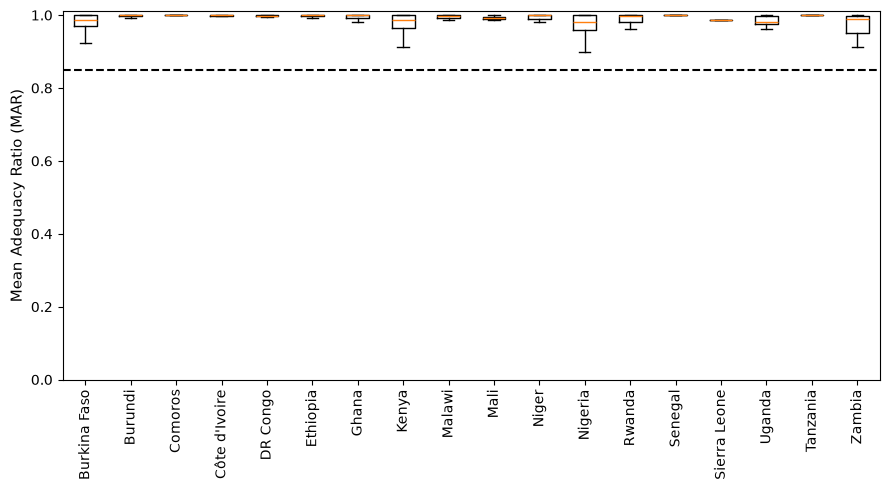

Median MAR by country, actual regional/yearly yields vs. the average-yield basket's MAR=1 target:
  Burkina Faso                        n= 130  median=0.986  min=0.760
  Burundi                             n= 160  median=1.000  min=0.906
  Comoros                             n=  10  median=1.000  min=0.997
  Côte d'Ivoire                       n=  10  median=0.999  min=0.998
  Democratic Republic of the Congo    n=  10  median=0.999  min=0.995
  Ethiopia                            n= 100  median=0.999  min=0.982
  Ghana                               n= 160  median=1.000  min=0.932
  Kenya                               n= 470  median=0.986  min=0.839
  Malawi                              n=  24  median=0.997  min=0.980
  Mali                                n=  90  median=0.993  min=0.973
  Niger                               n=  70  median=1.000  min=0.874
  Nigeria                             n= 370  median=0.981  min=0.813
  Rwanda                              n=  50  median=0.997  mi

In [5]:
filtered = [(c, v) for c, v in mar_values_per_country.items() if len(v) > 0]
labels, data = zip(*filtered)
labels = list(labels)
country_rename = {"United Republic of Tanzania": "Tanzania", "Democratic Republic of the Congo": "DR Congo"}
labels = [country_rename.get(l, l) for l in labels]

plt.figure(figsize=(9, 5))
plt.ylabel("Mean Adequacy Ratio (MAR)", fontsize=11)
plt.hlines(0.85, 0.5, len(labels) + 0.5, ls="--", colors="black")
# Set tick labels via plt.xticks() rather than boxplot()'s labels/tick_labels kwarg -
# that parameter was renamed between matplotlib versions, this form works on both.
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(labels) + 1), labels, rotation=90, fontsize=10)
plt.ylim(0, 1.01)
plt.tight_layout()
plt.show()

print("Median MAR by country, actual regional/yearly yields vs. the average-yield basket's MAR=1 target:")
for c, v in filtered:
    print(f"  {c:35s} n={len(v):4d}  median={np.median(v):.3f}  min={min(v):.3f}")

## Notes

For interactive exploration of the base model, see the companion
dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**
